# Notebook 2 — Adding Selectivity (the core Mamba idea)

**Goal:** turn the fixed SSM from Notebook 1 into a *selective* SSM — where the discretization step $\Delta_t$ and the input/output projections $B_t, C_t$ are **functions of the current input**, not fixed constants. Then test on a toy task that a non-selective SSM structurally cannot solve well.

This is the single idea that separates Mamba from earlier SSMs like S4.

In [1]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

torch.manual_seed(0)

## 1. Why fixed $\bar a, \bar b$ aren't enough

In Notebook 1, $\bar a, \bar b$ were the *same at every timestep* — the system treats every input identically. It has no way to say "this token matters, remember it" vs. "this token is noise, ignore it."

Mamba's fix: make $B, C, \Delta$ **functions of the input** $x_t$ (via small linear layers), so the effective discretized transition $\bar a_t = e^{\Delta_t A}$, $\bar b_t = \Delta_t B_t$ changes at every timestep, *based on what the model is currently looking at*. This is what "selective" means — conceptually similar to how attention weights depend on content, but computed through a recurrence instead of pairwise comparisons.

In [2]:
class SelectiveSSM(nn.Module):
    """A minimal selective SSM block: A is fixed & diagonal, but B, C, Delta
    are all produced by linear projections of the input at every timestep."""
    def __init__(self, in_dim, state_dim=8):
        super().__init__()
        self.state_dim = state_dim
        self.A_log = nn.Parameter(torch.log(torch.rand(state_dim) * 0.5 + 0.5))  # A = -exp(A_log) < 0
        self.in_proj = nn.Linear(in_dim, state_dim)   # -> B_t
        self.c_proj = nn.Linear(in_dim, state_dim)    # -> C_t
        self.delta_proj = nn.Linear(in_dim, 1)         # -> Delta_t (scalar step size)
        self.out_proj = nn.Linear(state_dim, 1)

    def forward(self, x, return_delta=False):
        # x: (batch, L, in_dim)
        B, L, _ = x.shape
        A = -torch.exp(self.A_log)                                   # (state_dim,)
        Bt = self.in_proj(x)                                          # (B, L, state_dim)
        Ct = self.c_proj(x)                                           # (B, L, state_dim)
        delta = torch.nn.functional.softplus(self.delta_proj(x))      # (B, L, 1), > 0

        h = torch.zeros(B, self.state_dim, device=x.device)
        ys, deltas = [], []
        for t in range(L):
            a_bar = torch.exp(delta[:, t] * A)          # (B, state_dim) -- CHANGES every step
            b_bar = delta[:, t] * Bt[:, t]                # (B, state_dim) -- CHANGES every step
            h = a_bar * h + b_bar
            y = (Ct[:, t] * h).sum(-1, keepdim=True)
            ys.append(y)
            deltas.append(delta[:, t])
        y = torch.stack(ys, dim=1)
        if return_delta:
            return y, torch.stack(deltas, dim=1)
        return y

## 2. A baseline: the *fixed* SSM from Notebook 1

Same recurrence shape, but $B, C, \Delta$ are learned once and shared across every timestep — exactly like Notebook 1, just with a learnable input gain. This is our control group: it can process the sequence, it just can't be *selective* about which tokens matter.

In [3]:
class FixedSSM(nn.Module):
    """Baseline: B, C, Delta are learned parameters, NOT functions of the input."""
    def __init__(self, in_dim, state_dim=8):
        super().__init__()
        self.state_dim = state_dim
        self.A_log = nn.Parameter(torch.log(torch.rand(state_dim) * 0.5 + 0.5))
        self.B = nn.Parameter(torch.randn(state_dim))
        self.C = nn.Parameter(torch.randn(state_dim))
        self.delta = nn.Parameter(torch.tensor(0.1))
        self.in_scalar = nn.Linear(in_dim, 1)   # still sees the input, just can't gate on it

    def forward(self, x):
        Bsz, L, _ = x.shape
        u = self.in_scalar(x)
        A = -torch.exp(self.A_log)
        delta = torch.nn.functional.softplus(self.delta)
        a_bar = torch.exp(delta * A)     # same every timestep
        b_bar = delta * self.B           # same every timestep
        h = torch.zeros(Bsz, self.state_dim)
        ys = []
        for t in range(L):
            h = a_bar * h + b_bar * u[:, t]
            y = (self.C * h).sum(-1, keepdim=True)
            ys.append(y)
        return torch.stack(ys, dim=1)

## 3. Toy task: selective copying

This is a small stand-in for the "selective copying" probe used in the Mamba paper. At a few random **marker** positions in the sequence, the input carries a signal value in $[-1, 1]$; everywhere else it's small background noise. The target at every timestep is *the most recent signal value seen so far*.

To solve this, the model must:
- recognize *which* tokens are markers (content-based selection),
- write the signal value into its state when it sees one,
- and otherwise leave the state alone (ignore the noise).

A fixed-parameter SSM has no mechanism to switch between "write" and "ignore" — it applies the same gain to every input, marker or not.

In [4]:
def make_batch(batch_size, L, n_markers=3):
    x = torch.randn(batch_size, L, 1) * 0.05  # background noise
    marker_flag = torch.zeros(batch_size, L, 1)
    target = torch.zeros(batch_size, L, 1)
    for b in range(batch_size):
        positions = torch.randperm(L - 1)[:n_markers].sort().values
        last_val = 0.0
        for t in range(L):
            if t in positions.tolist():
                val = torch.rand(1).item() * 2 - 1
                x[b, t, 0] = val
                marker_flag[b, t, 0] = 1.0
                last_val = val
            target[b, t, 0] = last_val
    model_input = torch.cat([x, marker_flag], dim=-1)  # (B, L, 2): [value, is_marker]
    return model_input, target

def train(model, steps=400, batch_size=32, L=20, lr=3e-3):
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    losses = []
    for step in range(steps):
        xb, yb = make_batch(batch_size, L)
        pred = model(xb)
        loss = ((pred - yb) ** 2).mean()
        opt.zero_grad()
        loss.backward()
        opt.step()
        losses.append(loss.item())
    return losses

Selective SSM  - final loss (avg last 20 steps): 0.0829
Fixed SSM      - final loss (avg last 20 steps): 0.0994


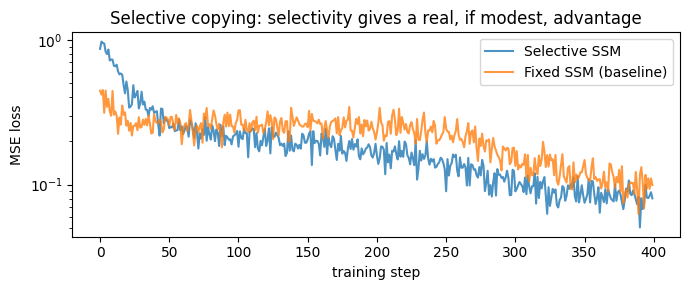

In [5]:
sel_model = SelectiveSSM(in_dim=2, state_dim=8)
fix_model = FixedSSM(in_dim=2, state_dim=8)

sel_losses = train(sel_model)
fix_losses = train(fix_model)

print(f"Selective SSM  - final loss (avg last 20 steps): {sum(sel_losses[-20:]) / 20:.4f}")
print(f"Fixed SSM      - final loss (avg last 20 steps): {sum(fix_losses[-20:]) / 20:.4f}")

plt.figure(figsize=(7, 3))
plt.plot(sel_losses, label="Selective SSM", alpha=0.8)
plt.plot(fix_losses, label="Fixed SSM (baseline)", alpha=0.8)
plt.xlabel("training step")
plt.ylabel("MSE loss")
plt.yscale("log")
plt.title("Selective copying: selectivity gives a real, if modest, advantage")
plt.legend()
plt.tight_layout()
plt.show()

## 4. Visualizing selectivity: does $\Delta_t$ spike at markers?

If the selective model has actually learned to "notice" markers, its per-timestep $\Delta_t$ (or the resulting update magnitude) should behave differently at marker positions than at noise positions. Let's check on one held-out sequence.

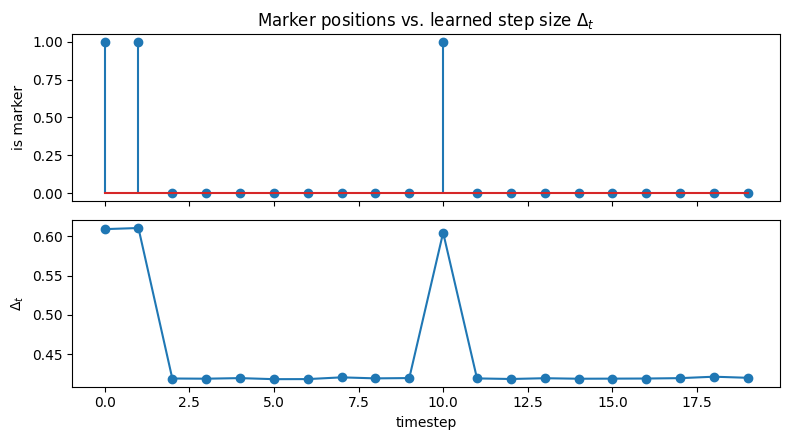

In [6]:
sel_model.eval()
with torch.no_grad():
    xb, yb = make_batch(1, 20)
    pred, deltas = sel_model(xb, return_delta=True)

marker_flag = xb[0, :, 1].numpy()
delta_trace = deltas[0, :, 0].numpy()

fig, axes = plt.subplots(2, 1, figsize=(8, 4.5), sharex=True)
axes[0].stem(marker_flag)
axes[0].set_ylabel("is marker")
axes[0].set_title("Marker positions vs. learned step size $\\Delta_t$")

axes[1].plot(delta_trace, marker="o")
axes[1].set_ylabel("$\\Delta_t$")
axes[1].set_xlabel("timestep")
plt.tight_layout()
plt.show()

## Exercise

1. Increase `n_markers` to 6 in `make_batch` and re-run training for both models. Does the gap between selective and fixed SSMs grow or shrink? Why?
2. The fixed SSM still receives `marker_flag` as part of its input (through `in_scalar`) — it just can't use it to *gate* its transition. Try removing `marker_flag` entirely from its input and see how much worse it gets.
3. `state_dim=8` was an arbitrary choice. Try `state_dim=2` for the selective model — can it still solve the task with `n_markers=3`? What does this tell you about state capacity vs. selectivity?